# GW analysis of monolayer and bilayer hBN

Yambo (Lumen fork, `bug-fixes` build) G0W0 calculations for the first benchmark of the project
(`docs/04_benchmark_systems.md`): explicit bilayer hBN vs monolayer + second layer as an effective substrate.
The GW parameters are converged on the monolayer (`ML_bot`) and used unchanged for all the systems.

Choices (user, 2026-11-11):
- k grids 18x18x1, 30x30x1, 42x42x1 (they contain K and M), nscf with 250 bands: upper bound of all the band
  parameters of the GW runs (`DFT_Analysis.ipynb`, section "NSCF on regular grids").
- Coulomb interaction: slab cutoff `CUTGeo='slab z'` and RIM on v in every run, RandQpts = 5000000, RandGvec = 100
  (values of the MoS2 study, not re-converged).
- HF runs with RIM only; all the GW (PPA) runs with RIM_W, RandGvecW = 10.

How to run: execute the cells in order; every dataset uses `skip=True` (existing results are not recomputed) and at
most 2 slurm jobs at a time (project rule: at most 2 nodes).

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import InputFiles as I, Calculators as C, Datasets as D, Parsers as P, Utilities as U
from mppi.Calculators import Tools
from mppi.Datasets import PostProcessing as PP
from mppi.Utilities import Constants as Const
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
# Calculator factory for ismhpc (32 cores per node, 32 MPI x 1 OMP for yambo)
module = '/home/dalessandro/module_script/yambo_module'

def yambo_code(nodes=1, partition='all12h', time='11:59:00', executable='yambo'):
    rr = C.RunRules(scheduler='slurm', partition=partition, memory='125000', time=time, nodes=nodes,
                    ntasks_per_node=32, cpus_per_task=1, omp_num_threads=1, pre_processing=module)
    return C.YamboCalculator(rr, executable=executable, activate_BeeOND=True)

## SAVE databases
One yambo folder per nscf: `MB_analysis/<nscf prefix>/SAVE`, built with `Tools.init_yambo_dir` (p2y + yambo setup
`r_setup`). p2y and the setup are serial and light: they run directly on the login node with 1 MPI and 1 OMP (user,
2026-11-11). Folders whose SAVE and `r_setup` already exist are skipped. The Lumen p2y ends with MPI_ABORT after
writing the databases: the SAVE is complete anyway (checked below). (Launching the OpenMPI p2y with `srun` hangs at
start-up on ismhpc.)

In [4]:
dft_dir = 'DFT_analysis'
mb_dir = 'MB_analysis'
saves = [('ML_bot', 18, 250), ('ML_bot', 30, 250), ('ML_bot', 42, 250),   # (system, k, bands) of the nscf runs
         ('AA1', 18, 400), ('AB', 18, 400), ('ML_bot', 24, 250)]

def nscf_name(system, k, nbnds):
    return 'kpoints_%s-nbnds_%s-%s' % (k, nbnds, system)

def yambo_dir(system, k, nbnds):
    return os.path.join(mb_dir, nscf_name(system, k, nbnds))

def build_save(system, k, nbnds):
    Tools.init_yambo_dir(yambo_dir=yambo_dir(system, k, nbnds),
                         input_dir=os.path.join(dft_dir, nscf_name(system, k, nbnds) + '.save'),
                         p2y_command='OMP_NUM_THREADS=1 mpirun -np 1 p2y',
                         yambo_command='OMP_NUM_THREADS=1 mpirun -np 1 yambo')

for s, k, nb in saves:
    build_save(s, k, nb)

SAVE folder MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_18-nbnds_400-AA1/SAVE already present. No operations performed.
SAVE folder MB_analysis/kpoints_18-nbnds_400-AB/SAVE already present. No operations performed.
Create the folder path MB_analysis/kpoints_24-nbnds_250-ML_bot
Executing command: cd MB_analysis/kpoints_24-nbnds_250-ML_bot; OMP_NUM_THREADS=1 mpirun -np 1 p2y -I ../../DFT_analysis/kpoints_24-nbnds_250-ML_bot.save


Build the r_setup in the yambo_dir path MB_analysis/kpoints_24-nbnds_250-ML_bot


In [5]:
def check_save(system, k, nbnds):
    folder = yambo_dir(system, k, nbnds)
    save = os.path.join(folder, 'SAVE')
    nwf = len([f for f in os.listdir(save) if f.startswith('ns.wf')])
    db = P.YamboDftParser(os.path.join(save, 'ns.db1'))
    with open(os.path.join(folder, 'r_setup')) as f: setup = f.read()
    print('%-30s %4d k points (IBZ) | %d bands | %d ns.wf files | r_setup %s'
          % (folder, len(db.get_kpoints()), db.nbands, nwf, 'ok' if 'Game Over' in setup else 'INCOMPLETE'))

for s, k, nb in saves:
    check_save(s, k, nb)

Parse file : MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_250-ML_bot   37 k points (IBZ) | 250 bands | 38 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_30-nbnds_250-ML_bot   91 k points (IBZ) | 250 bands | 92 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_42-nbnds_250-ML_bot  169 k points (IBZ) | 250 bands | 170 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_18-nbnds_400-AA1/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_400-AA1   37 k points (IBZ) | 400 bands | 38 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_18-nbnds_400-AB/SAVE/ns.db1
MB_analysis/kpoints_18-nbnds_400-AB   37 k points (IBZ) | 400 bands | 38 ns.wf files | r_setup ok
Parse file : MB_analysis/kpoints_24-nbnds_250-ML_bot/SAVE/ns.db1
MB_analysis/kpoints_24-nbnds_250-ML_bot   61 k points (IBZ) | 250 bands | 62 ns.wf files | r_setup ok


## HF on the monolayer: cutoff of the exchange term
`ML_bot`, k = 18x18x1 (`kpoints_18-nbnds_250-ML_bot`). Coulomb interaction: `CUTGeo='slab z'` + RIM (RandQpts = 5e6,
RandGvec = 100 RL, values fixed by the user). Scan of the exchange cutoff EXXRLvcs = VXCRLvcs (the same value for the
exchange and for the xc potential, which are subtracted). HF corrections of the top valence and bottom conduction
bands (4, 5) at all the 37 k points of the IBZ (cheap at this level): the control quantities are the gaps at K
(k index 37) and at $\Gamma$ (k index 1), and the single states at K.

Shared databases: yambo writes the new databases in the FIRST folder of the `-J` list and reads them from all the
folders. The RIM and cutoff databases are therefore computed once by a dedicated run (`yambo -r`, name and job
`ndb_rim_cutoff`) and read by all the following runs (`jobname=[name, 'ndb_rim_cutoff']`).

Parallel structure of the HF runlevel of this yambo (`-V all`): `SX_ROLEs`/`SX_CPU`. The role `b` runs over the
bands up to the highest corrected one (5 here), so it cannot take many tasks: the 32 MPI are split over the q
points (37) and the QP states (74): `SX_CPU = 8.4.1`.

In [6]:
hf_system, hf_k, hf_nbnds = 'ML_bot', 18, 250
run_dir = yambo_dir(hf_system, hf_k, hf_nbnds)
Gamma_index, K_index = 1, 37
start_band, stop_band = 4, 5          # top valence, bottom conduction (8 valence electrons)
RandQpts = 5000000
RandGvec = 100                         # RL

yambo_cmd = 'OMP_NUM_THREADS=1 mpirun -np 1 yambo'   # only to generate the inputs (login node)

def build_rim_input(folder=run_dir):
    # RIM and slab cutoff only: databases shared by all the runs of the folder (ndb_rim_cutoff)
    inp = I.YamboInput(args='%s -r -V all' % yambo_cmd, folder=folder)
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec)
    return inp

def run_rim(folder=run_dir):
    code = yambo_code()
    code.run(input=build_rim_input(folder), run_dir=folder, name='ndb_rim_cutoff', jobname='ndb_rim_cutoff', skip=True)

def build_hf_input(exx, folder=run_dir):
    inp = I.YamboInput(args='%s -r -x -V all' % yambo_cmd, folder=folder)
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec)
    inp.set_array_variables(units='Ha', EXXRLvcs=exx, VXCRLvcs=exx)
    inp.set_bandRange(start_band, stop_band)
    inp.set_scalar_variables(SX_ROLEs='q.qp.b', SX_CPU='8.4.1')    # 32 MPI on one node: q x qp (b has only 5 elements)
    return inp

build_hf_input(30.)

{'args': 'OMP_NUM_THREADS=1 mpirun -np 1 yambo -r -x -V all',
 'folder': 'MB_analysis/kpoints_18-nbnds_250-ML_bot',
 'filename': 'yambo.in',
 'arguments': ['rim_cut', 'HF_and_locXC', 'infver'],
 'variables': {'StdoHash': [40, ''],
  'Nelectro': [8.0, ''],
  'NelCond': [0.0, ''],
  'ElecTemp': [0.0, 'eV'],
  'BoseTemp': [-1.0, 'eV'],
  'OccTresh': [1e-05, ''],
  'NLogCPUs': [0, ''],
  'DBsIOoff': 'none',
  'DBsFRAGpm': 'none',
  'MEM_tresh': [88865, 'Kb'],
  'FFTGvecs': [12311, 'RL'],
  'PAR_def_mode': 'balanced',
  'SX_CPU': '8.4.1',
  'SX_ROLEs': 'q.qp.b',
  'SX_Threads': [0, ''],
  'BZINDX_CPU': '',
  'BZINDX_ROLEs': '',
  'RandQpts': [5000000, ''],
  'RandGvec': [100, 'RL'],
  'Em1Anys': [[0.0, 0.0, 0.0], ''],
  'IDEm1Ref': [0, ''],
  'CUTGeo': 'slab z',
  'CUTBox': [[0.0, 0.0, 0.0], ''],
  'CUTRadius': [0.0, ''],
  'CUTwsGvec': [0.7, ''],
  'EpsEnv': [1.0, ''],
  'EXXRLvcs': [30.0, 'Ha'],
  'VXCRLvcs': [30.0, 'Ha'],
  'QPkrange': [[1, 37, 4, 5], ''],
  'QPerange': [[1, 37, 0.0, -1.

In [7]:
EXXRLvcs = [10., 20., 30., 40., 50., 60.]   # Ha

run_rim()                    # shared RIM + cutoff databases (skipped if already computed)
code = yambo_code()
study = D.Dataset(run_dir=run_dir, num_tasks=2)
study.set_postprocessing_function(PP.yambo_parse_data)
for exx in EXXRLvcs:
    name = 'hf-exxrlvcs_%s' % exx
    assert len(name) <= 100
    study.append_run(id={'exx': exx}, input=build_hf_input(exx), runner=code, run_dir=run_dir, name=name,
                     jobname=[name, 'ndb_rim_cutoff'], skip=True)
results = study.run()

Initialize a Yambo calculator with scheduler slurm


Skip the run of ndb_rim_cutoff



        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        
Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2, 3, 4, 5] with the parallel task_groups [[0, 1], [2, 3], [4, 5]] 

Run the task [0, 1] 


Skip the run of

hf-exxrlvcs_10.0

... (9 outputs left out)

hf-exxrlvcs_60.0

Skip the run of

hf-exxrlvcs_50.0

Task [4, 5] ended 
 


EXXRLvcs =   10 Ha | HF gap at K = 13.1701 eV | at Gamma = 12.9471 eV | E_hf(K): v = -3.2180, c = 9.9521 eV
EXXRLvcs =   20 Ha | HF gap at K = 13.3226 eV | at Gamma = 13.0658 eV | E_hf(K): v = -3.3743, c = 9.9483 eV
EXXRLvcs =   30 Ha | HF gap at K = 13.3362 eV | at Gamma = 13.0686 eV | E_hf(K): v = -3.3850, c = 9.9512 eV
EXXRLvcs =   40 Ha | HF gap at K = 13.3354 eV | at Gamma = 13.0551 eV | E_hf(K): v = -3.3859, c = 9.9495 eV
EXXRLvcs =   50 Ha | HF gap at K = 13.3167 eV | at Gamma = 13.0191 eV | E_hf(K): v = -3.3662, c = 9.9506 eV
EXXRLvcs =   60 Ha | HF gap at K = 13.3207 eV | at Gamma = 12.9397 eV | E_hf(K): v = -3.3717, c = 9.9490 eV


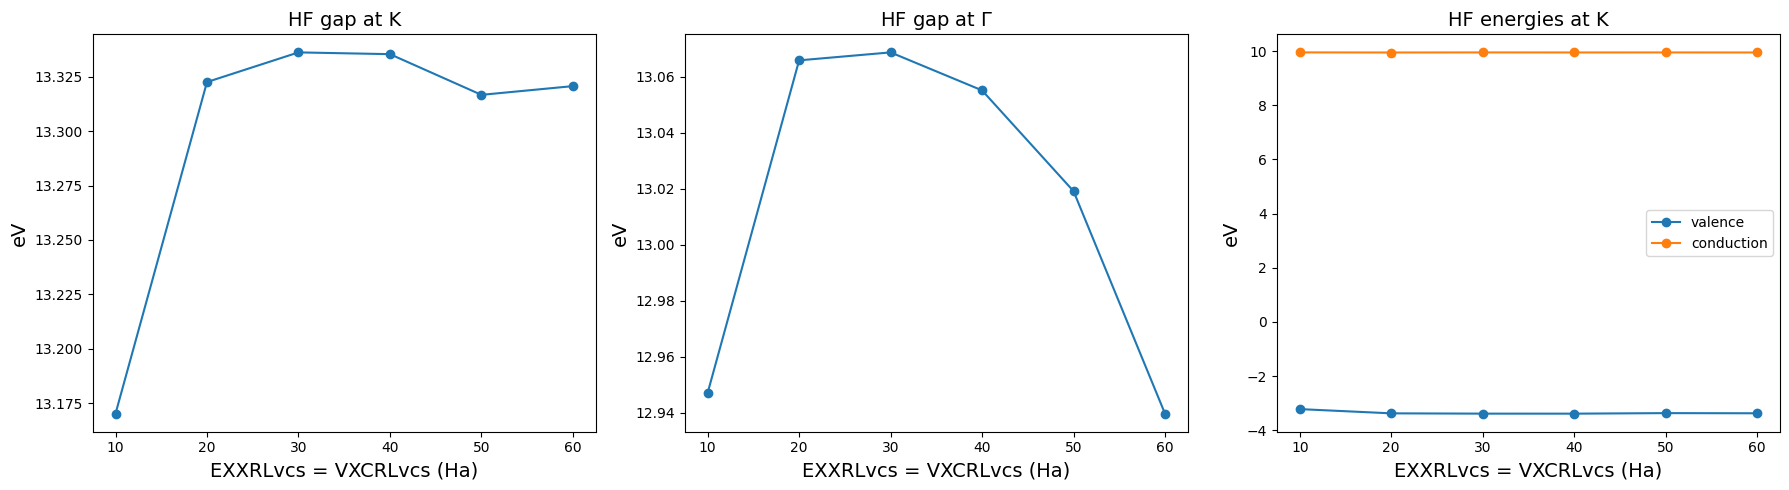

In [8]:
data = [study.fetch_results(id={'exx': exx})[0].data for exx in EXXRLvcs]
gap_K = [d.get_gap(k_full=K_index, band_full=start_band) for d in data]
gap_G = [d.get_gap(k_full=Gamma_index, band_full=start_band) for d in data]
v_K = [d.get_energy(K_index, start_band) for d in data]
c_K = [d.get_energy(K_index, stop_band) for d in data]
for exx, gk, gg, v, c in zip(EXXRLvcs, gap_K, gap_G, v_K, c_K):
    print('EXXRLvcs = %4.0f Ha | HF gap at K = %.4f eV | at Gamma = %.4f eV | E_hf(K): v = %.4f, c = %.4f eV'
          % (exx, gk, gg, v, c))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(EXXRLvcs, gap_K, 'o-'); ax[0].set_title('HF gap at K', size=14)
ax[1].plot(EXXRLvcs, gap_G, 'o-'); ax[1].set_title(r'HF gap at $\Gamma$', size=14)
ax[2].plot(EXXRLvcs, v_K, 'o-', label='valence'); ax[2].plot(EXXRLvcs, c_K, 'o-', label='conduction')
ax[2].set_title('HF energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('EXXRLvcs = VXCRLvcs (Ha)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18): the exchange term Sx is converged from 30-40 Ha (single states within 3 meV), while the
xc term Vxc keeps changing above 40 Ha, most of all for the nearly-free-electron conduction state at $\Gamma$
(-3.855, -3.842, -3.822, -3.741 eV at 30, 40, 50, 60 Ha): with EXXRLvcs = VXCRLvcs the gap at $\Gamma$ drops by
0.13 eV between 30 and 60 Ha, the gap at K oscillates by 20 meV. Interpretation (to check): the NFE state extends into
the vacuum, where the PBE potential of the very low density is noisy and has large-G components; truncating Vxc in G
then gives a cutoff-dependent matrix element, with no cancellation against Sx.

Check (user, 2026-11-11): Vxc with all the G vectors of the density (24949 RL, the default of this yambo, about
80 Ha: Vxc is local and its matrix element is then exact), with EXXRLvcs = 40 Ha and with EXXRLvcs = full.

In [9]:
vxc_full = 24949    # RL: all the G vectors of the density (default of yambo -V all)

def build_hf_input_rl(exx, vxc, exx_units='Ha', folder=run_dir):
    inp = build_hf_input(30., folder=folder)
    inp.set_array_variables(units=exx_units, EXXRLvcs=exx)
    inp.set_array_variables(units='RL', VXCRLvcs=vxc)
    return inp

checks = {'exx_40Ha-vxc_full': (40., 'Ha'), 'exx_full-vxc_full': (vxc_full, 'RL')}
code = yambo_code()
study_vxc = D.Dataset(run_dir=run_dir, num_tasks=2)
study_vxc.set_postprocessing_function(PP.yambo_parse_data)
for label, (exx, units) in checks.items():
    name = 'hf-%s' % label
    study_vxc.append_run(id=label, input=build_hf_input_rl(exx, vxc_full, exx_units=units), runner=code,
                         run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_vxc = study_vxc.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1] with the parallel task_groups [[0, 1]] 

Run the task [0, 1] 


Skip the run of

hf-exx_40Ha-vxc_full

Skip the run of

hf-exx_full-vxc_full

Task [0, 1] ended 
 


In [10]:
def hf_columns(name, k, b):
    # E0, Ehf, Vxc, Sx (eV) from the o-*.hf file of a run
    d = np.loadtxt(os.path.join(run_dir, name, 'o-%s.hf' % name), comments='#')
    row = d[(d[:, 0] == k) & (d[:, 1] == b)][0]
    return row[2:6]

runs = ['hf-exxrlvcs_%s' % e for e in EXXRLvcs] + ['hf-%s' % l for l in checks]
print('%-26s %9s %9s | %9s %9s %9s %9s | %9s %9s' % ('run', 'gap K', 'gap G', 'Vxc K v', 'Vxc G c', 'Sx K v', 'Sx G c',
                                                      'Ehf K v', 'Ehf K c'))
for name in runs:
    Kv, Kc = hf_columns(name, K_index, start_band), hf_columns(name, K_index, stop_band)
    Gv, Gc = hf_columns(name, Gamma_index, start_band), hf_columns(name, Gamma_index, stop_band)
    print('%-26s %9.4f %9.4f | %9.4f %9.4f %9.4f %9.4f | %9.4f %9.4f'
          % (name, Kc[1] - Kv[1], Gc[1] - Gv[1], Kv[2], Gc[2], Kv[3], Gc[3], Kv[1], Kc[1]))

run                            gap K     gap G |   Vxc K v   Vxc G c    Sx K v    Sx G c |   Ehf K v   Ehf K c
hf-exxrlvcs_10.0             13.1701   12.9471 |  -16.6122   -3.8532  -19.8302   -1.2982 |   -3.2180    9.9521
hf-exxrlvcs_20.0             13.3226   13.0658 |  -16.6119   -3.8550  -19.9862   -1.3021 |   -3.3743    9.9483
hf-exxrlvcs_30.0             13.3362   13.0686 |  -16.6191   -3.8553  -20.0041   -1.3022 |   -3.3850    9.9512
hf-exxrlvcs_40.0             13.3354   13.0551 |  -16.6207   -3.8424  -20.0066   -1.3022 |   -3.3859    9.9495
hf-exxrlvcs_50.0             13.3167   13.0191 |  -16.6407   -3.8224  -20.0068   -1.3022 |   -3.3662    9.9506
hf-exxrlvcs_60.0             13.3207   12.9397 |  -16.6351   -3.7410  -20.0068   -1.3022 |   -3.3717    9.9490
hf-exx_40Ha-vxc_full         13.3210   12.8630 |  -16.6348   -3.6631  -20.0066   -1.3022 |   -3.3718    9.9492
hf-exx_full-vxc_full         13.3212   12.8632 |  -16.6348   -3.6631  -20.0068   -1.3022 |   -3.3721    9.9492


Result of the check: with Vxc on all the G vectors of the density the results no longer depend on the exchange
cutoff (EXXRLvcs = 40 Ha and full differ by 0.3 meV): HF gap at K = 13.321 eV, at $\Gamma$ = 12.863 eV (k = 18).
The apparent plateau at 30-40 Ha of the EXXRLvcs = VXCRLvcs scan was an artefact of the truncated Vxc (+15 meV at K,
+0.2 eV at $\Gamma$).

Why: Vxc is a local potential; computed with all the G vectors of the density its matrix element is exactly the one
of the KS Hamiltonian that produced E0, so it is not a convergence parameter. Truncating it in G makes the result
cutoff dependent, most of all for the nearly-free-electron states that extend into the vacuum (conduction state at
$\Gamma$), where the PBE potential of the very low density has large-G components; the hoped-for cancellation of the
truncation errors of Sx and Vxc (EXXRLvcs = VXCRLvcs, MoS2 protocol) does not happen for these states.

**Choice (user, 2026-11-11): EXXRLvcs = VXCRLvcs = 24949 RL, all the G vectors of the density (the default of this
yambo).** Nothing to converge, and the cost is small: 17 s at k = 18 (6 s at EXXRLvcs = 40 Ha); the HF database is
computed once per k grid and then shared by the GW runs.

## HF on the monolayer: k grid
`ML_bot` on the 18, 30, 42 grids (24 added on 2026-11-12 with the GW k scan) with the chosen parameters (RIM 5e6/100, EXXRLvcs = VXCRLvcs = all the G vectors).
In each folder the RIM/cutoff databases are first computed by the dedicated run `ndb_rim_cutoff` (they depend on the
q grid), then the HF run reads them. The index of K in the IBZ list of each grid is found from the SAVE.

In [11]:
def find_k_index(folder, kpoint, atol=1e-5):
    # 1-based index of kpoint (cartesian, units 2pi/alat) in the IBZ list of the SAVE
    kpts = P.YamboDftParser(os.path.join(folder, 'SAVE', 'ns.db1')).get_kpoints()
    ind = [i for i, k in enumerate(kpts) if np.allclose(k[:2], kpoint[:2], atol=atol)]
    return ind[0] + 1 if ind else None

Kpoint = np.array([1./3., 1./np.sqrt(3.), 0.])
kpoints_hf = [18, 24, 30, 42]
hf_kgrid = {}
for k in kpoints_hf:
    folder = yambo_dir('ML_bot', k, 250)
    hf_kgrid[k] = {'folder': folder, 'K_index': find_k_index(folder, Kpoint)}
    print(k, hf_kgrid[k])

Parse file : MB_analysis/kpoints_18-nbnds_250-ML_bot/SAVE/ns.db1
18 {'folder': 'MB_analysis/kpoints_18-nbnds_250-ML_bot', 'K_index': 37}
Parse file : MB_analysis/kpoints_24-nbnds_250-ML_bot/SAVE/ns.db1
24 {'folder': 'MB_analysis/kpoints_24-nbnds_250-ML_bot', 'K_index': 61}
Parse file : MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE/ns.db1


30 {'folder': 'MB_analysis/kpoints_30-nbnds_250-ML_bot', 'K_index': 91}
Parse file : MB_analysis/kpoints_42-nbnds_250-ML_bot/SAVE/ns.db1
42 {'folder': 'MB_analysis/kpoints_42-nbnds_250-ML_bot', 'K_index': 169}


In [12]:
code = yambo_code()
study_hfk = D.Dataset(num_tasks=2)
study_hfk.set_postprocessing_function(PP.yambo_parse_data)
for k in kpoints_hf:
    folder = hf_kgrid[k]['folder']
    run_rim(folder)                       # one run per folder, before the HF runs that read it
    name = 'hf-exx_full-vxc_full'
    study_hfk.append_run(id={'k': k}, input=build_hf_input_rl(vxc_full, vxc_full, exx_units='RL', folder=folder),
                         runner=code, run_dir=folder, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_hfk = study_hfk.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks
Initialize a Yambo calculator with scheduler slurm


Skip the run of ndb_rim_cutoff



        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        


Initialize a Yambo calculator with scheduler slurm


run command: mpirun -np 32 yambo -F ndb_rim_cutoff.in -J ndb_rim_cutoff -C ndb_rim_cutoff
slurm submit:  cd MB_analysis/kpoints_24-nbnds_250-ML_bot ; sbatch job_ndb_rim_cutoff.sh
computation ndb_rim_cutoff is running...
Submitted batch job 60871


computation ndb_rim_cutoff ended

        There are no o-* files.
        Maybe you have performed a computation that does not create any output file or wait_end_run
        and/or the dry_run option are active.
        Otherwise a possible error has occured during the computation
        
Run performed in 52s


... (18 outputs left out)

hf-exx_full-vxc_full

Skip the run of

hf-exx_full-vxc_full

Task [2, 3] ended 
 


k = 18 (K index  37): HF gap at K = 13.3212 eV | at Gamma = 12.8632 eV | Ehf(K): v = -3.3721, c = 9.9492 eV
k = 24 (K index  61): HF gap at K = 13.3289 eV | at Gamma = 12.8674 eV | Ehf(K): v = -3.3769, c = 9.9519 eV
k = 30 (K index  91): HF gap at K = 13.3345 eV | at Gamma = 12.8714 eV | Ehf(K): v = -3.3814, c = 9.9531 eV
k = 42 (K index 169): HF gap at K = 13.3380 eV | at Gamma = 12.8732 eV | Ehf(K): v = -3.3836, c = 9.9544 eV


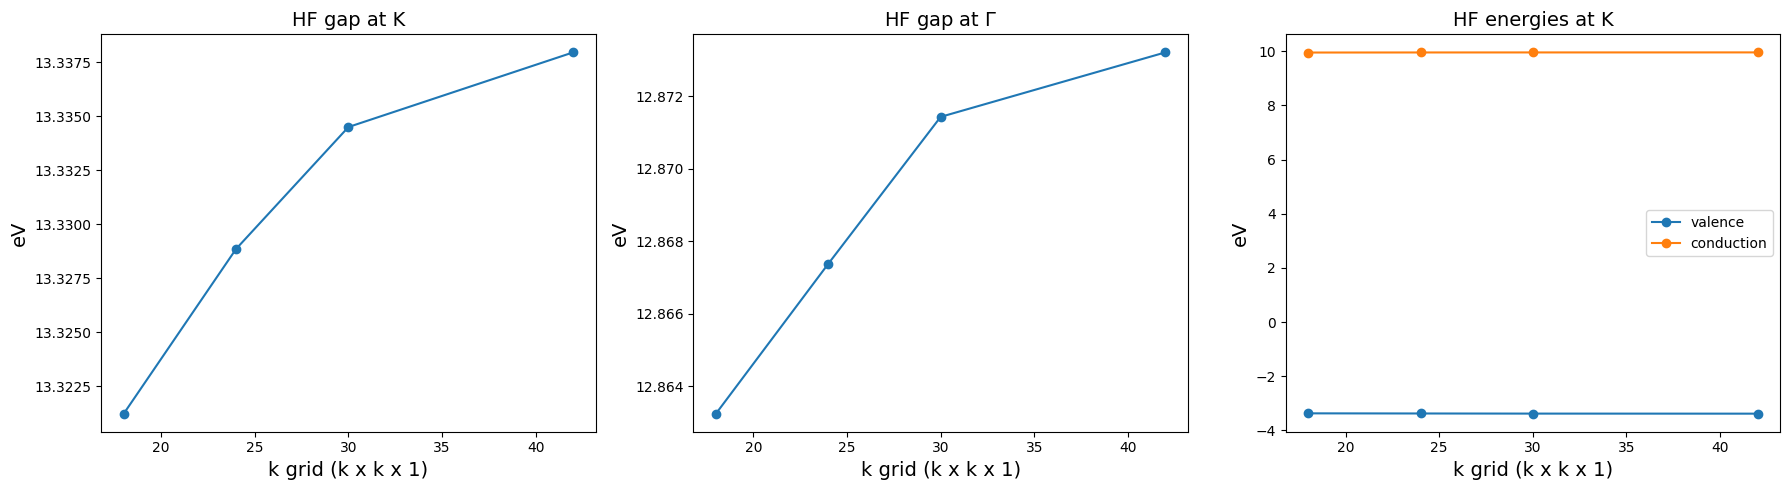

In [13]:
gap_K, gap_G, ev_K, ec_K = [], [], [], []
for k in kpoints_hf:
    folder, iK = hf_kgrid[k]['folder'], hf_kgrid[k]['K_index']
    d = np.loadtxt(os.path.join(folder, 'hf-exx_full-vxc_full', 'o-hf-exx_full-vxc_full.hf'), comments='#')
    E = {(int(r[0]), int(r[1])): r[3] for r in d}           # Ehf (eV)
    gap_K.append(E[(iK, stop_band)] - E[(iK, start_band)]); gap_G.append(E[(1, stop_band)] - E[(1, start_band)])
    ev_K.append(E[(iK, start_band)]); ec_K.append(E[(iK, stop_band)])
    print('k = %2d (K index %3d): HF gap at K = %.4f eV | at Gamma = %.4f eV | Ehf(K): v = %.4f, c = %.4f eV'
          % (k, iK, gap_K[-1], gap_G[-1], ev_K[-1], ec_K[-1]))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(kpoints_hf, gap_K, 'o-'); ax[0].set_title('HF gap at K', size=14)
ax[1].plot(kpoints_hf, gap_G, 'o-'); ax[1].set_title(r'HF gap at $\Gamma$', size=14)
ax[2].plot(kpoints_hf, ev_K, 'o-', label='valence'); ax[2].plot(kpoints_hf, ec_K, 'o-', label='conduction')
ax[2].set_title('HF energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('k grid (k x k x 1)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result: HF gaps (eV) of the monolayer vs k grid

| k grid | gap at K | gap at $\Gamma$ |
|---|---|---|
| 18x18x1 | 13.321 | 12.863 |
| 24x24x1 | 13.329 | 12.867 |
| 30x30x1 | 13.335 | 12.871 |
| 42x42x1 | 13.338 | 12.873 |

The HF gaps converge quickly with the slab cutoff and the RIM: 13 meV (K) and 8 meV ($\Gamma$) from 18 to 30, 3.5 and
2 meV from 30 to 42. The single HF states at K move by less than 12 meV overall. Costs: RIM 1-3 min, HF 17 s - 5 min
(18 -> 42). The k convergence of the GW corrections will be dominated by the screening (to be tested with RIM_W).
The 24 grid was added on 2026-11-12 with the GW k scan.

## GW (PPA) on the monolayer: size of the response matrix NGsBlkXp
`ML_bot`, k = 18x18x1. G0W0 with the Godby-Needs plasmon pole (`PPAPntXp` = 27.2 eV, default), Newton solver.
Coulomb interaction as in HF (slab z, RIM 5e6/100 from `ndb_rim_cutoff`) plus RIM_W with RandGvecW = 10 RL;
`LongDrXp = [1,1,0]` (in-plane field for the q -> 0 limit of a 2D system); EXXRLvcs = VXCRLvcs = all the G vectors
(default, HF choice above). QP corrections of bands 4, 5 at all the 37 k points of the IBZ (control quantities: gaps
at K and at $\Gamma$).

Scan: NGsBlkXp = 2, 4, 6, 8 Ha with BndsRnXp = GbndRnge = 250 (all the bands of the nscf). Each run computes
its own screening (PPA: `ndb.pp` + fragments), HF and RIM_W databases and reads only `ndb_rim_cutoff`, so the runs
are independent. After each run the screening and the RIM_W database built from it are moved to
`ndb_pp-ngsblkxp_<x>-bndsrnxp_250` (shared-database rule), to be read by the later GbndRnge scan.

Input: the RIM_W runlevel must be in the yambo command (`yambo -r -rw ...`): with `inp.activate_RIM_W()` only, the
reformat of the input (`yambo ... -F`) drops RIM_W and RandGvecW. RandGvec and RandGvecW are rounded by yambo to the
closed shells, 101 and 11 RL. Parallel structure (32 MPI): `X_and_IO_CPU = 1.1.4.8.1` (q.g.k.c.v),
`DIP_CPU = 4.8.1` (k.c.v), `SE_CPU = 2.2.8` (q.qp.b).

In [14]:
gw_cmd = '%s -r -rw -k hartee -dyson n -gw0 p -V all' % yambo_cmd
RandGvecW = 10                          # RL
LongDrXp = [1., 1., 0.]

def build_ppa_input(ngsblkxp, bndsrnxp, gbndrnge, folder=run_dir, kRange=(1, 37), terminator=False, kpoints=None,
                    randgvecw=None):
    # randgvecw: RL components of RIM_W (default RandGvecW)
    # kpoints: list of IBZ indices -> one QPkrange row per k point (convergence runs: only the checked points)
    inp = I.YamboInput(args=gw_cmd, folder=folder)
    inp.set_extendOut()
    inp.set_scalar_variables(CUTGeo='slab z')
    inp.set_array_variables(RandQpts=RandQpts)
    inp.set_array_variables(units='RL', RandGvec=RandGvec, RandGvecW=RandGvecW if randgvecw is None else randgvecw)
    inp.set_array_variables(units='Ha', NGsBlkXp=ngsblkxp)
    inp.set_array_variables(BndsRnXp=[1, bndsrnxp], GbndRnge=[1, gbndrnge], LongDrXp=LongDrXp)
    if terminator: inp.set_scalar_variables(GTermKind='BG')
    inp.set_kRange(*kRange)
    inp.set_bandRange(start_band, stop_band)
    if kpoints is not None:
        inp['variables']['QPkrange'] = [[[k, k, start_band, stop_band] for k in kpoints], '']
    inp.set_scalar_variables(X_and_IO_ROLEs='q.g.k.c.v', X_and_IO_CPU='1.1.4.8.1',
                             DIP_ROLEs='k.c.v', DIP_CPU='4.8.1', SE_ROLEs='q.qp.b', SE_CPU='2.2.8')
    return inp

def ppa_name(ngsblkxp, bndsrnxp, gbndrnge, terminator=False, randgvecw=None):
    return 'pp-ngsblkxp_%s-bndsrnxp_%s-gbndrnge_%s%s%s' % (ngsblkxp, bndsrnxp, gbndrnge, '-bg' if terminator else '',
                                                         '' if randgvecw is None else '-randgvecw_%s' % randgvecw)

def pp_name(ngsblkxp, bndsrnxp):
    return 'ndb_pp-ngsblkxp_%s-bndsrnxp_%s' % (ngsblkxp, bndsrnxp)

def share_pp(run_name, shared_name, folder=run_dir):
    # move the PPA screening (ndb.pp + fragments) and the RIM_W database built from it, of a completed run,
    # to the shared folder (skipped if already there)
    import glob, shutil
    src, dst = os.path.join(folder, run_name), os.path.join(folder, shared_name)
    files = glob.glob(os.path.join(src, 'ndb.pp*')) + glob.glob(os.path.join(src, 'ndb.RIM_W'))
    if os.path.isdir(dst) or not files: return
    os.makedirs(dst)
    for f in files: shutil.move(f, dst)
    print('moved %d files: %s -> %s' % (len(files), src, dst))

In [15]:
NGsBlkXp = [2., 4., 6., 8.]     # Ha (10 Ha run cancelled, choice 6 Ha: see below)
bnds_max = 250

code = yambo_code()
study_ngs = D.Dataset(run_dir=run_dir, num_tasks=2)
study_ngs.set_postprocessing_function(PP.yambo_parse_data)
for ngs in NGsBlkXp:
    name = ppa_name(ngs, bnds_max, bnds_max)
    study_ngs.append_run(id={'ngsblkxp': ngs}, input=build_ppa_input(ngs, bnds_max, bnds_max), runner=code,
                         run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_ngs = study_ngs.run()
for ngs in NGsBlkXp:
    share_pp(ppa_name(ngs, bnds_max, bnds_max), pp_name(ngs, bnds_max))

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2, 3] with the parallel task_groups [[0, 1], [2, 3]] 

Run the task [0, 1] 


Skip the run of

pp-ngsblkxp_2.0-bndsrnxp_250-gbndrnge_250

Skip the run of

pp-ngsblkxp_4.0-bndsrnxp_250-gbndrnge_250

... (2 outputs left out)

pp-ngsblkxp_6.0-bndsrnxp_250-gbndrnge_250

Skip the run of

pp-ngsblkxp_8.0-bndsrnxp_250-gbndrnge_250

Task [2, 3] ended 
 


NGsBlkXp =  2.0 Ha | GW gap at K = 7.2284 eV | at Gamma = 7.7945 eV | E_qp(K): v = -1.0124, c = 6.2160 eV
NGsBlkXp =  4.0 Ha | GW gap at K = 7.2206 eV | at Gamma = 8.0103 eV | E_qp(K): v = -1.1265, c = 6.0941 eV
NGsBlkXp =  6.0 Ha | GW gap at K = 7.2630 eV | at Gamma = 8.1605 eV | E_qp(K): v = -1.1830, c = 6.0800 eV
NGsBlkXp =  8.0 Ha | GW gap at K = 7.2650 eV | at Gamma = 8.1819 eV | E_qp(K): v = -1.1861, c = 6.0789 eV


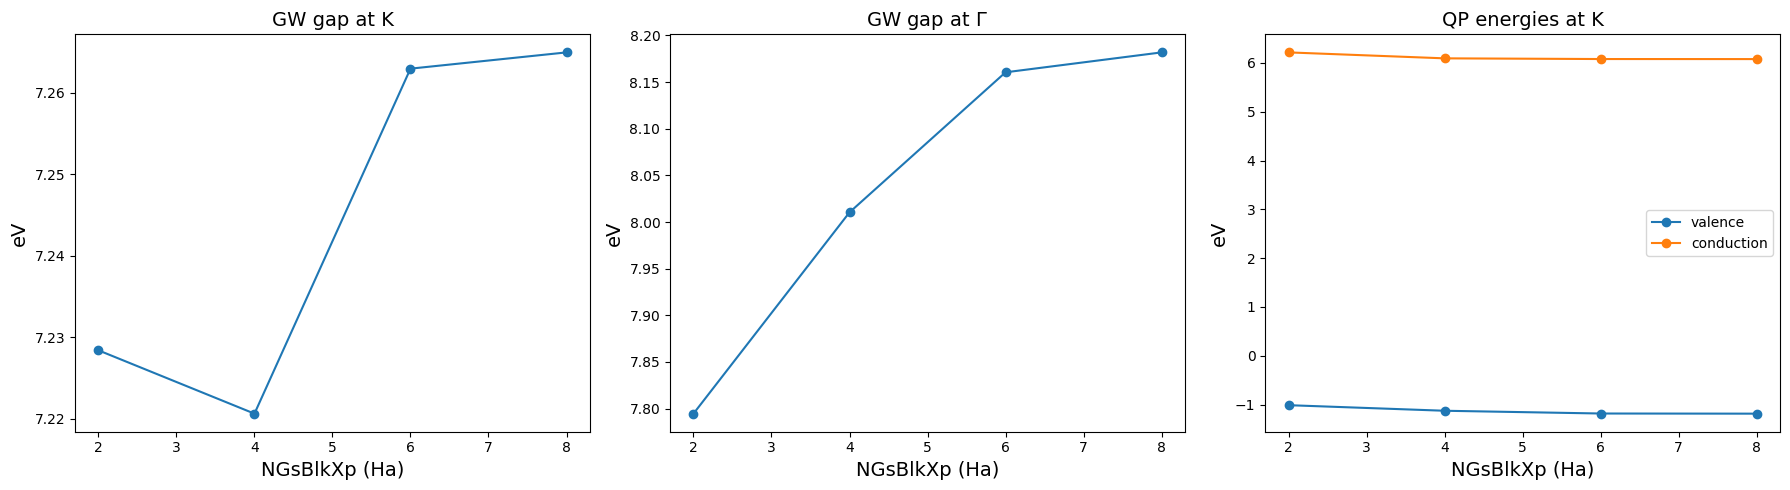

In [16]:
data = [study_ngs.fetch_results(id={'ngsblkxp': ngs})[0].data for ngs in NGsBlkXp]
gap_K = [d.get_gap(k_full=K_index, band_full=start_band) for d in data]
gap_G = [d.get_gap(k_full=Gamma_index, band_full=start_band) for d in data]
v_K = [d.get_energy(K_index, start_band) for d in data]
c_K = [d.get_energy(K_index, stop_band) for d in data]
for ngs, gk, gg, v, c in zip(NGsBlkXp, gap_K, gap_G, v_K, c_K):
    print('NGsBlkXp = %4.1f Ha | GW gap at K = %.4f eV | at Gamma = %.4f eV | E_qp(K): v = %.4f, c = %.4f eV'
          % (ngs, gk, gg, v, c))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(NGsBlkXp, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(NGsBlkXp, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(NGsBlkXp, v_K, 'o-', label='valence'); ax[2].plot(NGsBlkXp, c_K, 'o-', label='conduction')
ax[2].set_title('QP energies at K', size=14); ax[2].legend()
for a in ax: a.set_xlabel('NGsBlkXp (Ha)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18, BndsRnXp = GbndRnge = 250), QP energies in eV (zero = KS valence top at K):

| NGsBlkXp (Ha) | gap at K | gap at $\Gamma$ | $E_v(K)$ | $E_c(K)$ | $E_c(\Gamma)$ |
|---|---|---|---|---|---|
| 2 | 7.228 | 7.795 | -1.012 | 6.216 | 5.302 |
| 4 | 7.221 | 8.010 | -1.127 | 6.094 | 5.353 |
| 6 | 7.263 | 8.161 | -1.183 | 6.080 | 5.361 |
| 8 | 7.265 | 8.182 | -1.186 | 6.079 | 5.361 |

The gap at K is converged from 6 Ha (+2 meV from 6 to 8 Ha); the conduction state at $\Gamma$ (NFE) is converged within
1 meV, so the minimum (indirect K -> $\Gamma$) gap, about 6.54 eV, is stable from 6 Ha too. The gap at $\Gamma$ still moves
by 21 meV from 6 to 8 Ha because of the valence state at $\Gamma$ (deep, not relevant for the benchmark at K).
Costs (1 node): 12 min (2 Ha), 27 min (4 Ha), 1 h 33 min (6 Ha), 2 h 40 min (8 Ha).

**Choice (user, 2026-11-12): NGsBlkXp = 6 Ha** (the band parameters still have to be raised; a 10 Ha run was started
and cancelled, 12 Ha only if needed later). The screening (and RIM_W) databases of the scan are in
`ndb_pp-ngsblkxp_<x>-bndsrnxp_250`.

## GW (PPA) on the monolayer: bands in the response function BndsRnXp
`ML_bot`, k = 18x18x1, NGsBlkXp = 6 Ha, GbndRnge = 250 fixed; BndsRnXp = 100, 150, 200, 250 (the 250 point is the
6 Ha run of the NGsBlkXp scan). Rule (user, 2026-11-12): in the convergence runs the QP corrections are computed only
at the checked points, here $\Gamma$ and K (bands 4, 5; two `QPkrange` rows): Sigma then costs a few minutes instead
of 71 min for the 74 states of the IBZ (the QP energy of a state does not depend on the other states computed).
Each run computes its own screening (different BndsRnXp) and reads only `ndb_rim_cutoff`; afterwards `ndb.pp` and
`ndb.RIM_W` are moved to `ndb_pp-ngsblkxp_6.0-bndsrnxp_<n>`.

In [17]:
ngs_conv = 6.                            # Ha (choice above)
BndsRnXp = [100, 150, 200]               # + 250 from the NGsBlkXp scan
qp_kpoints = [Gamma_index, K_index]

code = yambo_code()
study_bnd = D.Dataset(run_dir=run_dir, num_tasks=2)
study_bnd.set_postprocessing_function(PP.yambo_parse_data)
for nb_x in BndsRnXp:
    name = ppa_name(ngs_conv, nb_x, bnds_max)
    study_bnd.append_run(id={'bndsrnxp': nb_x}, input=build_ppa_input(ngs_conv, nb_x, bnds_max, kpoints=qp_kpoints),
                         runner=code, run_dir=run_dir, name=name, jobname=[name, 'ndb_rim_cutoff'], skip=True)
results_bnd = study_bnd.run()
for nb_x in BndsRnXp:
    share_pp(ppa_name(ngs_conv, nb_x, bnds_max), pp_name(ngs_conv, nb_x))

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2] with the parallel task_groups [[0, 1], [2]] 

Run the task [0, 1] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_100-gbndrnge_250

Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_150-gbndrnge_250

Task [0, 1] ended 
 
Run the task [2] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_250

Task [2] ended 
 


BndsRnXp = 100 | GW gap at K = 7.2781 | at Gamma = 8.1206 | K->Gamma = 6.4668 | Ev(K) = -1.0873 Ec(K) = 6.1908 Ec(G) = 5.3794 eV
BndsRnXp = 150 | GW gap at K = 7.2654 | at Gamma = 8.1420 | K->Gamma = 6.5026 | Ev(K) = -1.1344 Ec(K) = 6.1310 Ec(G) = 5.3682 eV
BndsRnXp = 200 | GW gap at K = 7.2636 | at Gamma = 8.1527 | K->Gamma = 6.5287 | Ev(K) = -1.1652 Ec(K) = 6.0983 Ec(G) = 5.3635 eV
BndsRnXp = 250 | GW gap at K = 7.2630 | at Gamma = 8.1605 | K->Gamma = 6.5437 | Ev(K) = -1.1830 Ec(K) = 6.0800 Ec(G) = 5.3607 eV


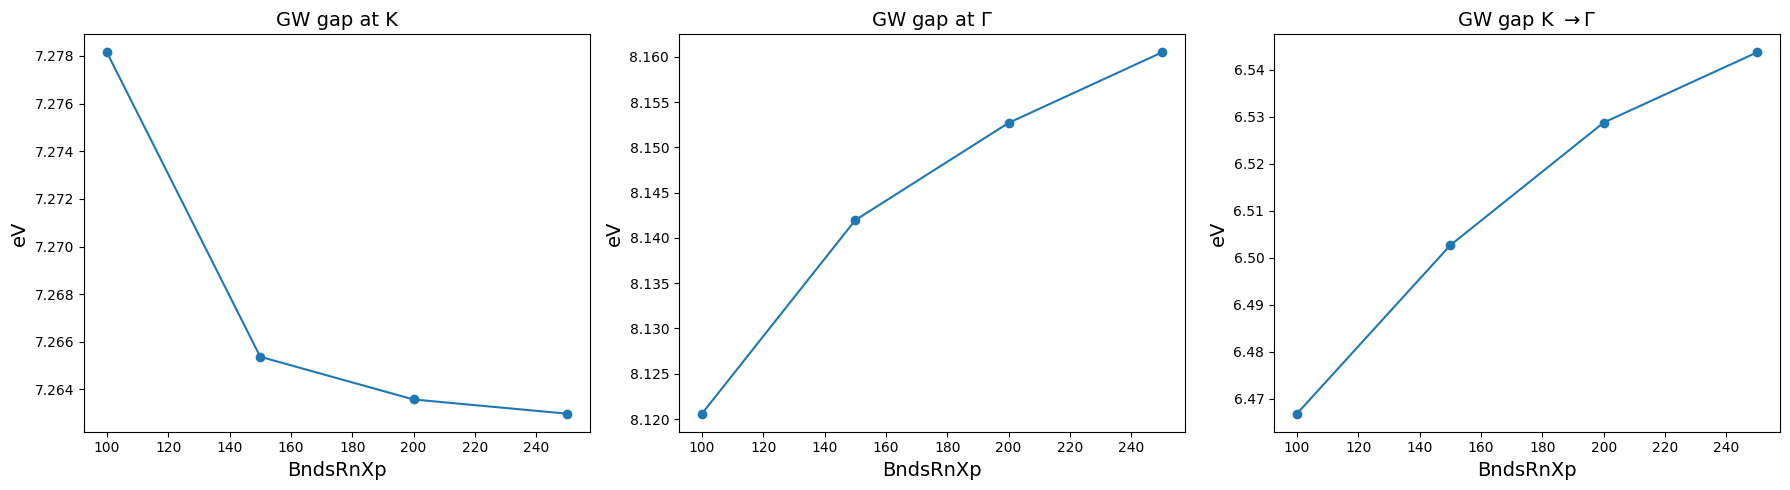

In [18]:
def qp_table(name):
    # E_qp (eV) of the o-*.qp file of a run, {(k, b): E}
    d = np.loadtxt(os.path.join(run_dir, name, 'o-%s.qp' % name), comments='#')
    return {(int(r[0]), int(r[1])): r[3] for r in d}

bnd_all = BndsRnXp + [bnds_max]
E = [qp_table(ppa_name(ngs_conv, nb_x, bnds_max)) for nb_x in bnd_all]
gap_K = [e[(K_index, stop_band)] - e[(K_index, start_band)] for e in E]
gap_G = [e[(Gamma_index, stop_band)] - e[(Gamma_index, start_band)] for e in E]
gap_KG = [e[(Gamma_index, stop_band)] - e[(K_index, start_band)] for e in E]
for nb_x, gk, gg, gi, e in zip(bnd_all, gap_K, gap_G, gap_KG, E):
    print('BndsRnXp = %3d | GW gap at K = %.4f | at Gamma = %.4f | K->Gamma = %.4f | Ev(K) = %.4f Ec(K) = %.4f Ec(G) = %.4f eV'
          % (nb_x, gk, gg, gi, e[(K_index, start_band)], e[(K_index, stop_band)], e[(Gamma_index, stop_band)]))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(bnd_all, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(bnd_all, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(bnd_all, gap_KG, 'o-'); ax[2].set_title(r'GW gap K $\to\Gamma$', size=14)
for a in ax: a.set_xlabel('BndsRnXp', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18, NGsBlkXp = 6 Ha, GbndRnge = 250), QP energies in eV (zero = KS valence top at K):

| BndsRnXp | gap at K | gap at $\Gamma$ | K -> $\Gamma$ | $E_v(K)$ | $E_c(K)$ | $E_c(\Gamma)$ |
|---|---|---|---|---|---|---|
| 100 | 7.278 | 8.121 | 6.467 | -1.087 | 6.191 | 5.379 |
| 150 | 7.265 | 8.142 | 6.503 | -1.134 | 6.131 | 5.368 |
| 200 | 7.264 | 8.153 | 6.529 | -1.165 | 6.098 | 5.364 |
| 250 | 7.263 | 8.161 | 6.544 | -1.183 | 6.080 | 5.361 |

The gap at K is converged from 150 bands (2 meV from 150 to 250). The single QP energies at K are not: from 200 to
250 bands both move down by about 18 meV ($E_v$ -18, $E_c$ -18 meV) and the shift cancels in the gap. The gap at
$\Gamma$ (+8 meV from 200 to 250) and the indirect K -> $\Gamma$ gap (+15 meV, through $E_v(K)$) still drift.
The 250 point is the 6 Ha run of the NGsBlkXp scan (QP at all the IBZ states). Costs (1 node, QP at Gamma and K only): 13 min (100), 21 min (150), 27 min (200).

**Choice (user, 2026-11-12): BndsRnXp = 200** (working value: the gap at K is converged; the screening databases of all four values are in `ndb_pp-ngsblkxp_6.0-bndsrnxp_<n>`).

## GW (PPA) on the monolayer: bands in the self-energy GbndRnge, with and without the BG terminator
`ML_bot`, k = 18x18x1, NGsBlkXp = 6 Ha, BndsRnXp = 200; GbndRnge = 100, 150, 200, 250, without and with the
Bruneval-Gonze terminator (`GTermKind='BG'`, default `GTermEn`). QP corrections only at $\Gamma$ and K (bands 4, 5).
All the runs read the same screening (`ndb_pp-ngsblkxp_6.0-bndsrnxp_200`, in the `jobname` list) and compute only
Sigma, so they run two at a time without writing any shared database. The point GbndRnge = 250 without terminator is
the run `pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_250` of the BndsRnXp scan. GbndRnge is limited to 250 by the nscf:
if the curves are not flat there, a new nscf at k = 18 with more bands is needed.

In [19]:
bnd_x_conv = 200                         # BndsRnXp (choice above)
GbndRnge = [100, 150, 200, 250]
shared_pp = pp_name(ngs_conv, bnd_x_conv)

code = yambo_code()
study_gbnd = D.Dataset(run_dir=run_dir, num_tasks=2)
study_gbnd.set_postprocessing_function(PP.yambo_parse_data)
for term in [False, True]:
    for nb_s in GbndRnge:
        if nb_s == bnds_max and not term: continue   # computed in the BndsRnXp scan
        name = ppa_name(ngs_conv, bnd_x_conv, nb_s, terminator=term)
        study_gbnd.append_run(id={'gbndrnge': nb_s, 'bg': term},
                              input=build_ppa_input(ngs_conv, bnd_x_conv, nb_s, terminator=term, kpoints=qp_kpoints),
                              runner=code, run_dir=run_dir, name=name, jobname=[name, shared_pp, 'ndb_rim_cutoff'],
                              skip=True)
results_gbnd = study_gbnd.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2, 3, 4, 5, 6] with the parallel task_groups [[0, 1], [2, 3], [4, 5], [6]] 

Run the task [0, 1] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_100

Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_150

... (10 outputs left out)

Task [4, 5] ended 
 
Run the task [6] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_250-bg

Task [6] ended 
 


no terminator
  GbndRnge = 100 | GW gap at K = 7.1999 | at Gamma = 7.8771 | K->Gamma = 6.2956 | Ev(K) = -0.8992 Ec(K) = 6.3007 Ec(G) = 5.3964 eV
  GbndRnge = 150 | GW gap at K = 7.2244 | at Gamma = 8.0114 | K->Gamma = 6.4111 | Ev(K) = -1.0320 Ec(K) = 6.1923 Ec(G) = 5.3790 eV
  GbndRnge = 200 | GW gap at K = 7.2476 | at Gamma = 8.1000 | K->Gamma = 6.4836 | Ev(K) = -1.1143 Ec(K) = 6.1333 Ec(G) = 5.3693 eV
  GbndRnge = 250 | GW gap at K = 7.2636 | at Gamma = 8.1527 | K->Gamma = 6.5287 | Ev(K) = -1.1652 Ec(K) = 6.0983 Ec(G) = 5.3635 eV
BG terminator
  GbndRnge = 100 | GW gap at K = 7.3615 | at Gamma = 8.3451 | K->Gamma = 6.6948 | Ev(K) = -1.3480 Ec(K) = 6.0135 Ec(G) = 5.3467 eV
  GbndRnge = 150 | GW gap at K = 7.3440 | at Gamma = 8.3214 | K->Gamma = 6.6742 | Ev(K) = -1.3262 Ec(K) = 6.0177 Ec(G) = 5.3479 eV
  GbndRnge = 200 | GW gap at K = 7.3371 | at Gamma = 8.3147 | K->Gamma = 6.6677 | Ev(K) = -1.3195 Ec(K) = 6.0175 Ec(G) = 5.3482 eV
  GbndRnge = 250 | GW gap at K = 7.3345 | at Gamma = 8.

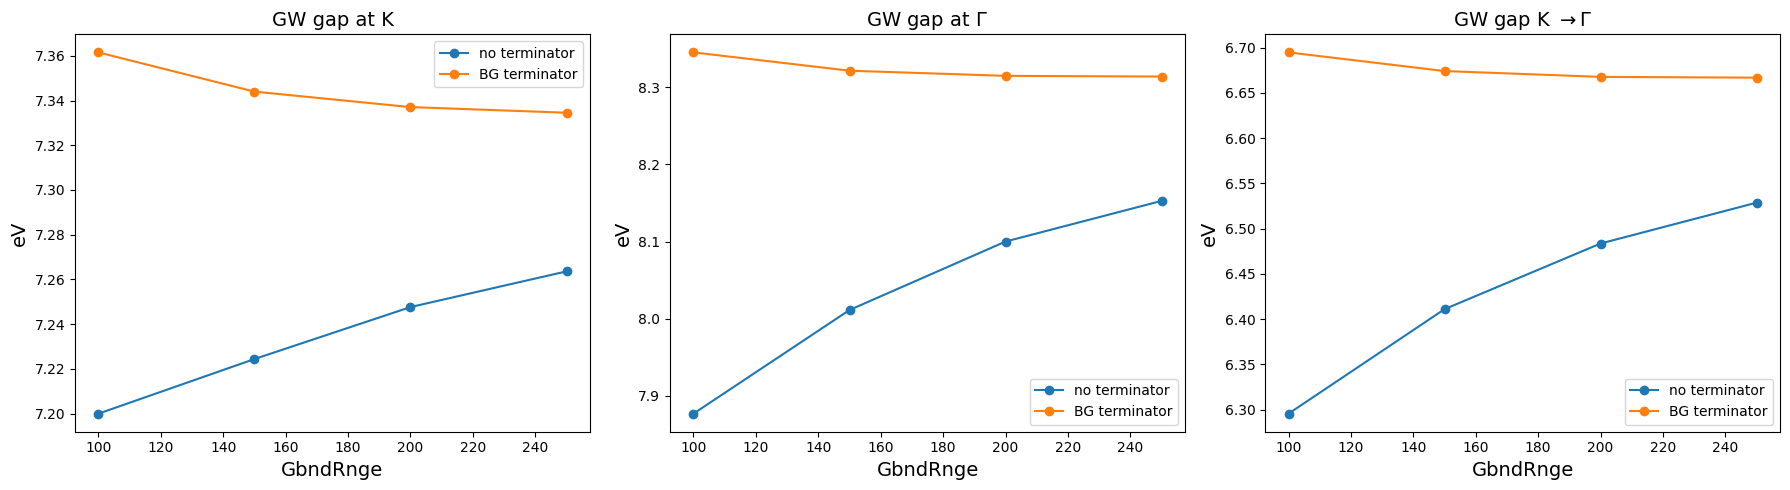

In [20]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
for term, lab in [(False, 'no terminator'), (True, 'BG terminator')]:
    E = [qp_table(ppa_name(ngs_conv, bnd_x_conv, nb_s, terminator=term)) for nb_s in GbndRnge]
    gap_K = [e[(K_index, stop_band)] - e[(K_index, start_band)] for e in E]
    gap_G = [e[(Gamma_index, stop_band)] - e[(Gamma_index, start_band)] for e in E]
    gap_KG = [e[(Gamma_index, stop_band)] - e[(K_index, start_band)] for e in E]
    print(lab)
    for nb_s, gk, gg, gi, e in zip(GbndRnge, gap_K, gap_G, gap_KG, E):
        print('  GbndRnge = %3d | GW gap at K = %.4f | at Gamma = %.4f | K->Gamma = %.4f | Ev(K) = %.4f Ec(K) = %.4f Ec(G) = %.4f eV'
              % (nb_s, gk, gg, gi, e[(K_index, start_band)], e[(K_index, stop_band)], e[(Gamma_index, stop_band)]))
    ax[0].plot(GbndRnge, gap_K, 'o-', label=lab)
    ax[1].plot(GbndRnge, gap_G, 'o-', label=lab)
    ax[2].plot(GbndRnge, gap_KG, 'o-', label=lab)
ax[0].set_title('GW gap at K', size=14); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].set_title(r'GW gap K $\to\Gamma$', size=14)
for a in ax: a.set_xlabel('GbndRnge', size=14); a.set_ylabel('eV', size=14); a.legend()
fig.tight_layout()

Result of the scan (k = 18, NGsBlkXp = 6 Ha, BndsRnXp = 200), QP energies in eV (zero = KS valence top at K):

| GbndRnge | BG | gap at K | gap at $\Gamma$ | K -> $\Gamma$ | $E_v(K)$ | $E_c(K)$ | $E_c(\Gamma)$ |
|---|---|---|---|---|---|---|---|
| 100 | no | 7.200 | 7.877 | 6.296 | -0.899 | 6.301 | 5.396 |
| 150 | no | 7.224 | 8.011 | 6.411 | -1.032 | 6.192 | 5.379 |
| 200 | no | 7.248 | 8.100 | 6.484 | -1.114 | 6.133 | 5.369 |
| 250 | no | 7.264 | 8.153 | 6.529 | -1.165 | 6.098 | 5.364 |
| 100 | yes | 7.362 | 8.345 | 6.695 | -1.348 | 6.014 | 5.347 |
| 150 | yes | 7.344 | 8.321 | 6.674 | -1.326 | 6.018 | 5.348 |
| 200 | yes | 7.337 | 8.315 | 6.668 | -1.320 | 6.018 | 5.348 |
| 250 | yes | 7.335 | 8.314 | 6.667 | -1.319 | 6.016 | 5.348 |

Without terminator the gap at K still grows by 16 meV from 200 to 250 bands (slow 1/N convergence; the single energies
move by 35-50 meV). With the BG terminator the convergence is fast and from above: from 200 to 250 bands the gap at K
changes by 2.6 meV, the gap at $\Gamma$ and K -> $\Gamma$ by 1 meV, the single energies by at most 2 meV. A fit
$a + b/N$ of the last two (three) points without terminator extrapolates the gap at K to 7.33 (7.32) eV, consistent
with the BG value: the terminator is reliable here and no nscf with more bands is needed.
Costs (1 node, QP at Gamma and K only, screening read from `ndb_pp-ngsblkxp_6.0-bndsrnxp_200`): 2-5 min per run.

**Choice (user, 2026-11-12): GbndRnge = 200 with the BG terminator.**

## GW (PPA) on the monolayer: RIM_W components RandGvecW
`ML_bot`, k = 18x18x1, NGsBlkXp = 6 Ha, BndsRnXp = 200, GbndRnge = 200 + BG; RandGvecW = 1, 10, 20, 30 RL (rounded by
yambo to closed shells; the 10 RL point, i.e. 11 RL, is the run `pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg` of the
GbndRnge scan). QP only at $\Gamma$ and K. The runs read `ndb.pp` from `ndb_pp-ngsblkxp_6.0-bndsrnxp_200`. The
`ndb.RIM_W` of the shared folder (11 RL) is reused by yambo when RandGvecW <= 11 RL, using only its first components
(the RIM_W integral is element-wise in G, G', so this equals a fresh calculation; checked: the 1 RL run differs from the
11 RL one); for a larger RandGvecW yambo flags the mismatch (`*ERR* Screening RL components`) and recomputes
`ndb.RIM_W` in the run's own folder (checked in the reports, a few seconds).

In [21]:
gbnd_conv = 200                          # GbndRnge (choice above), with the BG terminator
RandGvecW_scan = [1, 20, 30]             # RL; + 10 (= 11 RL) from the GbndRnge scan

code = yambo_code()
study_rimw = D.Dataset(run_dir=run_dir, num_tasks=2)
study_rimw.set_postprocessing_function(PP.yambo_parse_data)
for rw in RandGvecW_scan:
    name = ppa_name(ngs_conv, bnd_x_conv, gbnd_conv, terminator=True, randgvecw=rw)
    study_rimw.append_run(id={'randgvecw': rw},
                          input=build_ppa_input(ngs_conv, bnd_x_conv, gbnd_conv, terminator=True, kpoints=qp_kpoints,
                                                randgvecw=rw),
                          runner=code, run_dir=run_dir, name=name, jobname=[name, shared_pp, 'ndb_rim_cutoff'],
                          skip=True)
results_rimw = study_rimw.run()

Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1, 2] with the parallel task_groups [[0, 1], [2]] 

Run the task [0, 1] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg-randgvecw_1

Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg-randgvecw_20

Task [0, 1] ended 
 
Run the task [2] 


Skip the run of

pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg-randgvecw_30

Task [2] ended 
 


RandGvecW =  1 | GW gap at K = 7.3967 | at Gamma = 8.3689 | K->Gamma = 6.7201 | Ev(K) = -1.3491 Ec(K) = 6.0475 Ec(G) = 5.3710 eV
RandGvecW = 10 | GW gap at K = 7.3371 | at Gamma = 8.3147 | K->Gamma = 6.6677 | Ev(K) = -1.3195 Ec(K) = 6.0175 Ec(G) = 5.3482 eV
RandGvecW = 20 | GW gap at K = 7.3368 | at Gamma = 8.3147 | K->Gamma = 6.6677 | Ev(K) = -1.3195 Ec(K) = 6.0173 Ec(G) = 5.3482 eV
RandGvecW = 30 | GW gap at K = 7.3366 | at Gamma = 8.3145 | K->Gamma = 6.6675 | Ev(K) = -1.3194 Ec(K) = 6.0172 Ec(G) = 5.3481 eV


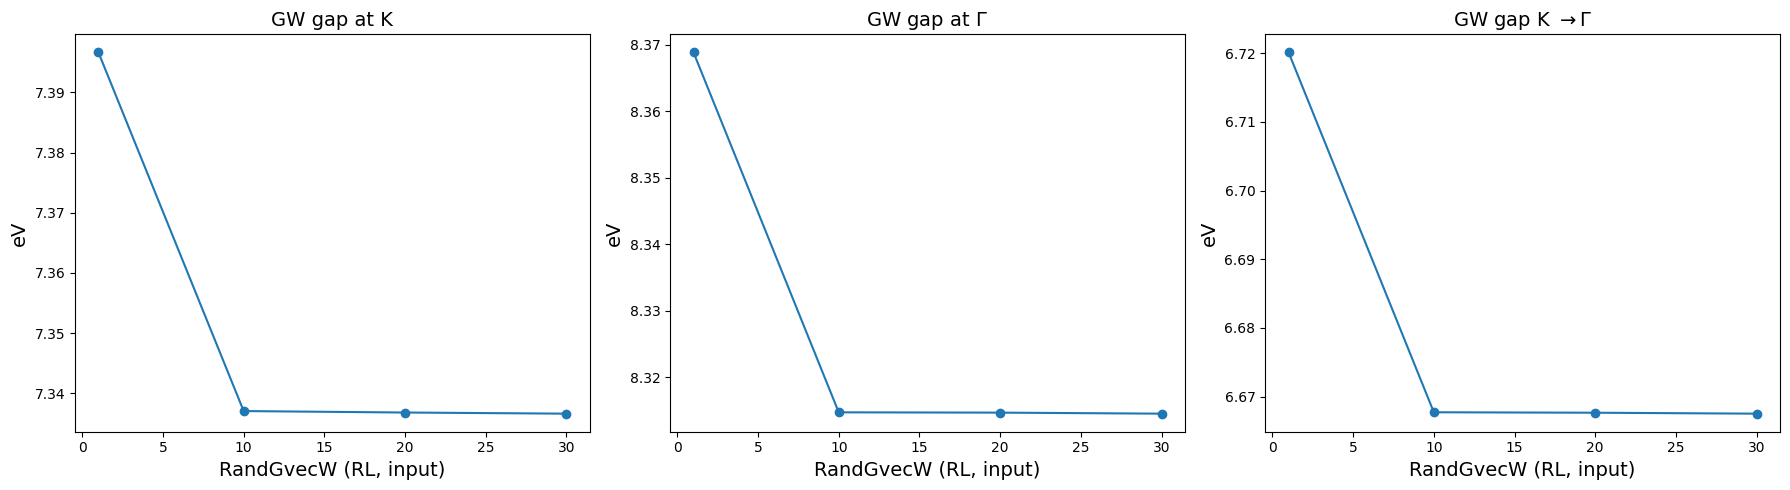

In [22]:
rw_all = [1, 10, 20, 30]
names = {rw: ppa_name(ngs_conv, bnd_x_conv, gbnd_conv, terminator=True, randgvecw=None if rw == RandGvecW else rw)
         for rw in rw_all}
E = [qp_table(names[rw]) for rw in rw_all]
gap_K = [e[(K_index, stop_band)] - e[(K_index, start_band)] for e in E]
gap_G = [e[(Gamma_index, stop_band)] - e[(Gamma_index, start_band)] for e in E]
gap_KG = [e[(Gamma_index, stop_band)] - e[(K_index, start_band)] for e in E]
for rw, gk, gg, gi, e in zip(rw_all, gap_K, gap_G, gap_KG, E):
    print('RandGvecW = %2d | GW gap at K = %.4f | at Gamma = %.4f | K->Gamma = %.4f | Ev(K) = %.4f Ec(K) = %.4f Ec(G) = %.4f eV'
          % (rw, gk, gg, gi, e[(K_index, start_band)], e[(K_index, stop_band)], e[(Gamma_index, stop_band)]))

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(rw_all, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(rw_all, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(rw_all, gap_KG, 'o-'); ax[2].set_title(r'GW gap K $\to\Gamma$', size=14)
for a in ax: a.set_xlabel('RandGvecW (RL, input)', size=14); a.set_ylabel('eV', size=14)
fig.tight_layout()

Result of the scan (k = 18, NGsBlkXp = 6 Ha, BndsRnXp = 200, GbndRnge = 200 + BG), QP energies in eV (zero = KS
valence top at K); RandGvecW in the input, rounded by yambo to 1, 11, 25, 37 RL:

| RandGvecW | gap at K | gap at $\Gamma$ | K -> $\Gamma$ | $E_v(K)$ | $E_c(K)$ | $E_c(\Gamma)$ |
|---|---|---|---|---|---|---|
| 1 | 7.397 | 8.369 | 6.720 | -1.349 | 6.048 | 5.371 |
| 10 | 7.337 | 8.315 | 6.668 | -1.320 | 6.018 | 5.348 |
| 20 | 7.337 | 8.315 | 6.668 | -1.320 | 6.017 | 5.348 |
| 30 | 7.337 | 8.315 | 6.668 | -1.319 | 6.017 | 5.348 |

RandGvecW = 10 (11 RL) is converged: from 10 to 30 every quantity changes by less than 0.5 meV, while the head-only
RIM_W (1 RL) is off by 60 meV in the gap at K. Costs: 5-7 min per run (RIM_W recomputed in a few seconds).
**RandGvecW = 10 kept** (default of the project).

## GW (PPA) on the monolayer: k grid
`ML_bot` with the converged parameters: NGsBlkXp = 6 Ha, BndsRnXp = 200, GbndRnge = 200 + BG, RandGvecW = 10 RL
(RIM 5e6/100, EXXRLvcs = VXCRLvcs = all the G vectors). Grids 18 (the run `pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg`
above), 24, 30 (user, 2026-11-12; the SAVE at 42 is available if the 24 -> 30 change is not small).
QP only at $\Gamma$ and K (index of K from the SAVE of each grid). Each run computes its own screening and RIM_W
(they depend on the q grid) and reads `ndb_rim_cutoff` of its folder; afterwards `ndb.pp` and `ndb.RIM_W` are moved to
`ndb_pp-ngsblkxp_6.0-bndsrnxp_200` of that folder. Expected cost of the response (Xo, ~ N_q(IBZ) x N_k(BZ)): 22.5 min
at k = 18, ~1.1 h at 24, ~2.6 h at 30 (1 node).

In [23]:
kpoints_gw = [24, 30]                    # + 18 from the scans above
gw_kgrid = {18: {'folder': run_dir, 'K_index': K_index}}
for k in kpoints_gw:
    folder = yambo_dir('ML_bot', k, 250)
    gw_kgrid[k] = {'folder': folder, 'K_index': find_k_index(folder, Kpoint)}
    print(k, gw_kgrid[k])
name_kgrid = ppa_name(ngs_conv, bnd_x_conv, gbnd_conv, terminator=True)

code = yambo_code()
study_gwk = D.Dataset(num_tasks=2)
study_gwk.set_postprocessing_function(PP.yambo_parse_data)
for k in kpoints_gw:
    folder = gw_kgrid[k]['folder']
    study_gwk.append_run(id={'k': k},
                         input=build_ppa_input(ngs_conv, bnd_x_conv, gbnd_conv, folder=folder, terminator=True,
                                               kpoints=[Gamma_index, gw_kgrid[k]['K_index']]),
                         runner=code, run_dir=folder, name=name_kgrid, jobname=[name_kgrid, 'ndb_rim_cutoff'], skip=True)
results_gwk = study_gwk.run()
for k in kpoints_gw:
    share_pp(name_kgrid, pp_name(ngs_conv, bnd_x_conv), folder=gw_kgrid[k]['folder'])

Parse file : MB_analysis/kpoints_24-nbnds_250-ML_bot/SAVE/ns.db1
24 {'folder': 'MB_analysis/kpoints_24-nbnds_250-ML_bot', 'K_index': 61}
Parse file : MB_analysis/kpoints_30-nbnds_250-ML_bot/SAVE/ns.db1
30 {'folder': 'MB_analysis/kpoints_30-nbnds_250-ML_bot', 'K_index': 91}
Initialize a Yambo calculator with scheduler slurm
Initialize a Dataset with 2 parallel tasks


Run the selection [0, 1] with the parallel task_groups [[0, 1]] 

Run the task [0, 1] 


run command: mpirun -np 32 yambo -F pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg.in -J "pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg,ndb_rim_cutoff" -C pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg

slurm submit: 

cd MB_analysis/kpoints_24-nbnds_250-ML_bot ; sbatch job_pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg.sh

computation pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg is running...

... (7 outputs left out)

computation pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg ended

Run performed in 02h-30m

Task [0, 1] ended 
 
moved 63 files: MB_analysis/kpoints_24-nbnds_250-ML_bot/pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg -> MB_analysis/kpoints_24-nbnds_250-ML_bot/ndb_pp-ngsblkxp_6.0-bndsrnxp_200


moved 93 files: MB_analysis/kpoints_30-nbnds_250-ML_bot/pp-ngsblkxp_6.0-bndsrnxp_200-gbndrnge_200-bg -> MB_analysis/kpoints_30-nbnds_250-ML_bot/ndb_pp-ngsblkxp_6.0-bndsrnxp_200


k = 18 (K index  37): GW gap at K = 7.3371 | at Gamma = 8.3147 | K->Gamma = 6.6677 | Ev(K) = -1.3195 Ec(K) = 6.0175 eV
k = 24 (K index  61): GW gap at K = 7.3343 | at Gamma = 8.3129 | K->Gamma = 6.6665 | Ev(K) = -1.3199 Ec(K) = 6.0144 eV
k = 30 (K index  91): GW gap at K = 7.3355 | at Gamma = 8.3148 | K->Gamma = 6.6683 | Ev(K) = -1.3220 Ec(K) = 6.0135 eV


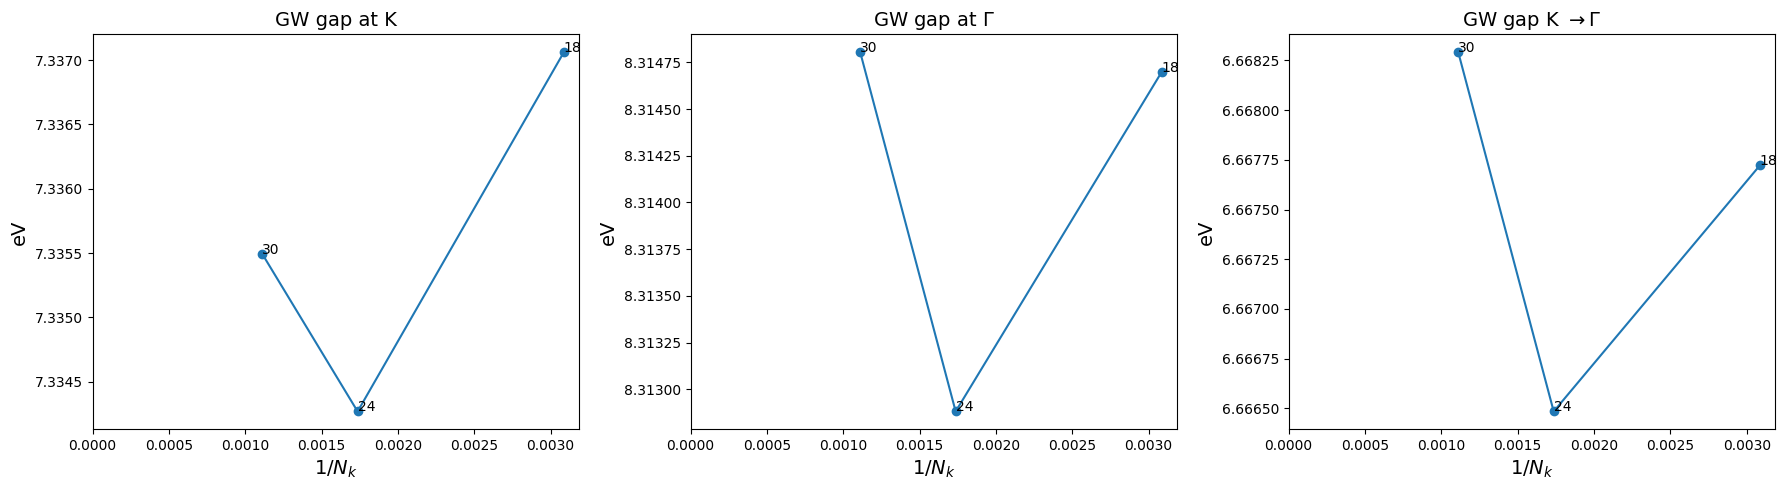

In [24]:
k_all = [18] + kpoints_gw
gap_K, gap_G, gap_KG, ev_K, ec_K = [], [], [], [], []
for k in k_all:
    folder, iK = gw_kgrid[k]['folder'], gw_kgrid[k]['K_index']
    d = np.loadtxt(os.path.join(folder, name_kgrid, 'o-%s.qp' % name_kgrid), comments='#')
    E = {(int(r[0]), int(r[1])): r[3] for r in d}
    gap_K.append(E[(iK, stop_band)] - E[(iK, start_band)]); gap_G.append(E[(1, stop_band)] - E[(1, start_band)])
    gap_KG.append(E[(1, stop_band)] - E[(iK, start_band)]); ev_K.append(E[(iK, start_band)]); ec_K.append(E[(iK, stop_band)])
    print('k = %2d (K index %3d): GW gap at K = %.4f | at Gamma = %.4f | K->Gamma = %.4f | Ev(K) = %.4f Ec(K) = %.4f eV'
          % (k, iK, gap_K[-1], gap_G[-1], gap_KG[-1], ev_K[-1], ec_K[-1]))

x = [1. / k**2 for k in k_all]           # 1/N_k
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
ax[0].plot(x, gap_K, 'o-'); ax[0].set_title('GW gap at K', size=14)
ax[1].plot(x, gap_G, 'o-'); ax[1].set_title(r'GW gap at $\Gamma$', size=14)
ax[2].plot(x, gap_KG, 'o-'); ax[2].set_title(r'GW gap K $\to\Gamma$', size=14)
for a in ax:
    a.set_xlabel(r'$1/N_k$', size=14); a.set_ylabel('eV', size=14); a.set_xlim(left=0)
    for k, xx in zip(k_all, x): a.annotate(str(k), (xx, a.get_lines()[0].get_ydata()[k_all.index(k)]))
fig.tight_layout()

Result (NGsBlkXp = 6 Ha, BndsRnXp = 200, GbndRnge = 200 + BG, RandGvecW = 10 RL), QP energies in eV (zero = KS valence
top at K):

| k grid | gap at K | gap at $\Gamma$ | K -> $\Gamma$ | $E_v(K)$ | $E_c(K)$ |
|---|---|---|---|---|---|
| 18x18x1 | 7.337 | 8.315 | 6.668 | -1.320 | 6.018 |
| 24x24x1 | 7.334 | 8.313 | 6.667 | -1.320 | 6.014 |
| 30x30x1 | 7.336 | 8.315 | 6.668 | -1.322 | 6.014 |

With RIM_W the GW gaps are converged already at k = 18: from 18 to 30 they change by less than 3 meV, without a
trend (no extrapolation needed); the single QP energies at K by 2-4 meV. The GW gap at K moves less than the HF gap
(+14 meV from 18 to 30): the k dependence of the exchange is compensated by that of the correlation. The 42 grid is
not needed. Costs (1 node): nscf at k = 24 6 min; GW 1 h 14 min (k = 24, Xo 1 h 08 min) and 2 h 30 min (k = 30,
Xo 2 h 19 min). The screening databases are in `ndb_pp-ngsblkxp_6.0-bndsrnxp_200` of each folder.

**Converged GW parameters of the monolayer** (k = 18 grid): NGsBlkXp = 6 Ha, BndsRnXp = 200, GbndRnge = 200 + BG,
RandGvecW = 10 RL, RIM 5e6/100, EXXRLvcs = VXCRLvcs = all the G vectors; GW gap at K = 7.337 eV (KS 4.714 eV).